# Bombs: card strength in draft decks

How much of a drafter's win rate comes from the strength of the cards in their deck, and how much do decks differ in
card strength? This notebook rates every card by GIH WR, for every set we have, and then scores each Premier Draft deck by the
average rating of its cards.

* **GIH WR** is the win rate of games in which the card was in the opening hand or drawn (17Lands' headline card stat).
* **Normalized GIH WR** is the card's GIH WR **minus the set's average game win rate**, in percentage points (pp). 17Lands
  users win ~55% of games and the exact baseline differs by set and event, so raw GIH WR isn't comparable across
  sets.
* **Shrinkage.** Per-card estimates are noisy, and the extremes are biased outward. So every card is shrunk toward the
  average for its rarity (empirical Bayes, normal–normal) before use.

Sections:
1. Per-card GIH WR for every set and event
2. Deck strength: the average normalized GIH WR of the cards in each deck, how it relates to win rate, and how much it
   varies between drafters

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import card_metadata
from openlane.deckstrength import aligned, flag
from openlane.games import game_path

OUT = ROOT / "results" / "bombs"
OUT.mkdir(parents=True, exist_ok=True)
SETS = ["NEO", "ONE", "MOM", "WOE", "LCI", "MKM", "OTJ", "BLB", "DSK", "FDN", "DFT", "TDM", "FIN", "EOE", "TLA",
        "ECL", "TMT", "SOS", "MSH"]
EVENTS = ["PremierDraft", "Sealed"]
MIN_GIH = 200          # games with the card in hand; below this a card is dropped
K = 5

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
EV_COLOR = {"PremierDraft": BLUE, "Sealed": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(60); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(40)
pl.Config.set_tbl_hide_dataframe_shape(True); pl.Config.set_float_precision(2)

polars.config.Config

## 1. Per-card GIH WR for every set and event

For each game file, one row per card: games in hand, GIH WR, normalized GIH WR (pp above the set average), and the
shrunk version.

The shrinkage is done within each rarity. Each card's observed value is $x_i$ with sampling variance $s_i^2 = p(1-p)/n_i$. Within a rarity the
true values are assumed $\sim N(\mu_r, \tau_r^2)$, with $\mu_r$ the precision-weighted mean and
$\tau_r^2 = \max(\mathrm{Var}(x) - \overline{s^2}, 0.25\,\mathrm{pp}^2)$. The posterior mean is
$\mu_r + \frac{\tau_r^2}{\tau_r^2 + s_i^2}(x_i - \mu_r)$. Rarity matters here: mythics average several pp above commons, so
a common-wide prior would over-shrink the bombs.

Basic lands are dropped. Results are cached to `results/bombs/`.

In [2]:
BASICS = ["Plains", "Island", "Swamp", "Mountain", "Forest"]


def eb_shrink(x, se2, groups):
    out = np.empty_like(x)
    for g in np.unique(groups):
        m = groups == g
        w = 1 / se2[m]
        mu = (w * x[m]).sum() / w.sum()
        tau2 = max(x[m].var() - se2[m].mean(), 0.25)
        out[m] = mu + tau2 / (tau2 + se2[m]) * (x[m] - mu)
    return out


def rate_cards(g, s, names):
    # per-card GIH WR on the games in g; norm and norm_eb in pp above g's average win rate
    won = flag(g["won"]).astype(np.float32)
    hand = ((aligned(g, "opening_hand_", names) + aligned(g, "drawn_", names)) > 0).astype(np.float32)
    n = hand.sum(0)
    base = won.mean()
    meta = card_metadata(names, s)
    df = pl.DataFrame({"name": names, "rarity": meta["rarity"], "n_gih": n.astype(np.int64),
                       "gih_wr": (won @ hand).astype(np.float64) / np.maximum(n, 1)})
    df = df.filter((pl.col("n_gih") >= MIN_GIH) & (pl.col("rarity") != "basic") & ~pl.col("name").is_in(BASICS))
    x = (df["gih_wr"].to_numpy() - base) * 100
    se2 = df["gih_wr"].to_numpy() * (1 - df["gih_wr"].to_numpy()) / df["n_gih"].to_numpy() * 1e4
    return df.with_columns(pl.lit(float(base) * 100).alias("set_wr"), pl.Series("norm", x),
                           pl.Series("norm_eb", eb_shrink(x, se2, df["rarity"].to_numpy())))


def card_table(s, event):
    path = OUT / f"{s}.{event}.cards.parquet"
    if path.exists():
        return pl.read_parquet(path)
    g = pl.read_parquet(game_path(s, event))
    names = [c[len("drawn_"):] for c in g.columns if c.startswith("drawn_")]
    df = rate_cards(g, s, names).with_columns(
        pl.lit(s).alias("set"), pl.lit(event).alias("event"), pl.lit(g.height).alias("n_games"),
        pl.lit(str(g["draft_time"].min())[:10]).alias("first_day"))
    df.write_parquet(path)
    return df


cards = pl.concat([card_table(s, e) for s in SETS for e in EVENTS], how="diagonal")
info = (cards.group_by("set", "event").agg(pl.first("n_games"), pl.first("set_wr"), pl.first("first_day"),
                                            pl.len().alias("cards"))
        .pivot(on="event", index="set", values=["n_games", "set_wr", "cards", "first_day"]))
SETS = info.sort("first_day_PremierDraft")["set"].to_list()   # release order
info.sort("first_day_PremierDraft").select(
    "set", pl.col("first_day_PremierDraft").alias("first day"),
    "n_games_PremierDraft", "n_games_Sealed", "set_wr_PremierDraft", "set_wr_Sealed", "cards_PremierDraft", "cards_Sealed")

set,first day,n_games_PremierDraft,n_games_Sealed,set_wr_PremierDraft,set_wr_Sealed,cards_PremierDraft,cards_Sealed
str,str,i32,i32,f64,f64,u32,u32
"""NEO""","""2022-02-10""",630450,58903,55.60,54.33,280,276
"""ONE""","""2023-02-02""",583077,56654,54.75,56.34,260,253
"""MOM""","""2023-04-13""",1246850,61294,54.76,55.40,341,331
"""WOE""","""2023-08-31""",1024028,57618,55.20,56.57,307,275
"""LCI""","""2023-11-09""",823614,54609,55.34,55.62,285,277
"""MKM""","""2024-02-06""",964377,52764,54.98,54.52,303,264
"""OTJ""","""2024-04-16""",1172393,54832,54.14,55.29,368,324
"""BLB""","""2024-07-30""",931230,50658,54.60,55.49,268,256
"""DSK""","""2024-09-24""",1011949,55079,54.48,55.86,275,258


## 2. Deck strength: average normalized GIH WR of the deck's cards

For every Premier Draft game, the deck's **score** is the mean shrunk normalized GIH WR of the cards in its main deck,
weighted by number of copies. Basic lands are left out, and so are the few cards with fewer than `MIN_GIH` games.
`cover` is the share of the deck's nonbasic cards that have a rating.

**Cross-fitting.** If a card's GIH WR were computed from the same games it's scoring, every deck's own result would leak into its
score. So drafts (draft_ids) are split into two random halves, and each half's decks are scored with card ratings
estimated from the other half only.

A drafter can rebuild between games, so the score is per game. For drafter-level numbers, it's averaged over that drafter's games.
Per-game scores are cached to `results/bombs/{set}.PremierDraft.decks.parquet`.

In [3]:
def deck_scores(s, event="PremierDraft"):
    path = OUT / f"{s}.{event}.decks.parquet"
    if path.exists():
        return pl.read_parquet(path)
    g = pl.read_parquet(game_path(s, event))
    names = [c[len("drawn_"):] for c in g.columns if c.startswith("drawn_")]
    idx = {n: j for j, n in enumerate(names)}
    nonbasic = ~np.isin(names, BASICS)
    deck = aligned(g, "deck_", names).astype(np.float32)
    half = g["draft_id"].hash(seed=7).to_numpy() % 2
    score, cover = np.full(g.height, np.nan), np.zeros(g.height)
    for h in (0, 1):
        r = rate_cards(g.filter(pl.Series(half != h)), s, names)   # ratings from the other half
        v = np.full(len(names), np.nan)
        v[[idx[n] for n in r["name"]]] = r["norm_eb"].to_numpy()
        rated, m = ~np.isnan(v), half == h
        d = deck[m]
        k = d[:, rated].sum(1)
        score[m] = d[:, rated] @ v[rated] / np.maximum(k, 1)
        cover[m] = k / np.maximum(d[:, nonbasic].sum(1), 1)
    out = pl.DataFrame({"draft_id": g["draft_id"], "won": flag(g["won"]), "score": score, "cover": cover})
    out.write_parquet(path)
    return out


decks = {s: deck_scores(s) for s in SETS}
print(f"cover (share of nonbasic deck cards with a rating): median "
      f"{np.median(np.concatenate([d['cover'].to_numpy() for d in decks.values()])):.3f}")

cover (share of nonbasic deck cards with a rating): median 1.000


### 2a. Score vs win rate

Per set, game-level win rate in bins of deck score, shown as pp above the set average on both axes. The thin lines are
individual sets and the thick line pools all of them. A score of +1 means the deck's cards average 1pp above the set's
average GIH WR.

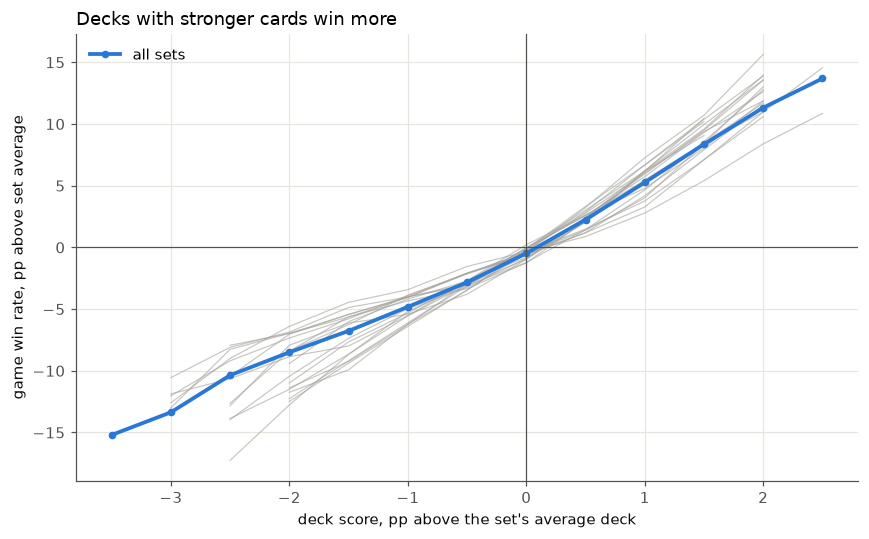

In [4]:
games = pl.concat([d.with_columns(pl.lit(s).alias("set")) for s, d in decks.items()]).filter(pl.col("cover") >= 0.9)
games = games.with_columns(((pl.col("won").cast(pl.Float64) - pl.col("won").cast(pl.Float64).mean().over("set")) * 100)
                           .alias("won_c"),
                           (pl.col("score") - pl.col("score").mean().over("set")).alias("score_c"))
games = games.with_columns((pl.col("score_c") * 2).round().truediv(2).alias("bin"))   # 0.5pp bins

fig, ax = plt.subplots(figsize=(8, 5))
for s in SETS:
    b = games.filter(pl.col("set") == s).group_by("bin").agg(pl.col("won_c").mean(), pl.len()).filter(pl.col("len") >= 2000).sort("bin")
    ax.plot(b["bin"], b["won_c"], color=GRAY, lw=0.8, alpha=0.6)
b = games.group_by("bin").agg(pl.col("won_c").mean(), pl.len()).filter(pl.col("len") >= 5000).sort("bin")
ax.plot(b["bin"], b["won_c"], "o-", color=BLUE, lw=2.5, ms=4, label="all sets")
ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("deck score, pp above the set's average deck")
ax.set_ylabel("game win rate, pp above set average")
ax.set_title("Decks with stronger cards win more", loc="left")
ax.legend(); plt.tight_layout(); plt.show()

### 2b. Per-set numbers

* **sd game**: SD of deck score across games.
* **sd drafter / p10 / p90**: spread of the drafter-average score (drafters with ≥ 3 games), centered on the set mean.
* **r game**: correlation between deck score and the game result (0/1).
* **slope**: pp of game win rate per +1pp of deck score (linear regression on games).
* **sd true WR**: SD of drafters' true win rates. It's the observed SD of per-drafter win rate with the binomial noise
  from their few games subtracted.
* **share explained**: Var(slope × drafter score) / Var(true WR), i.e. how much of the real spread in drafter win
  rates the deck score accounts for.

In [5]:
rows = []
for s in SETS:
    g = games.filter(pl.col("set") == s)
    x, y = g["score"].to_numpy(), g["won"].to_numpy().astype(np.float64)
    slope = np.cov(x, y)[0, 1] / x.var() * 100
    dr = (g.group_by("draft_id").agg(pl.col("score").mean(), pl.col("won").cast(pl.Float64).mean().alias("wr"),
                                     pl.len().alias("n")).filter(pl.col("n") >= 3))
    ds, wr, n = dr["score"].to_numpy(), dr["wr"].to_numpy(), dr["n"].to_numpy()
    var_true = wr.var() - np.mean(wr.mean() * (1 - wr.mean()) / n)
    c = ds - ds.mean()
    rows.append({"set": s, "games": g.height, "drafters": dr.height, "sd game": x.std(), "sd drafter": ds.std(),
                 "p10": np.percentile(c, 10), "p90": np.percentile(c, 90), "r game": np.corrcoef(x, y)[0, 1],
                 "slope": slope, "sd true WR": np.sqrt(var_true) * 100,
                 "share explained": (slope * ds.std()) ** 2 / (var_true * 1e4)})
per_set = pl.DataFrame(rows)
per_set.write_csv(OUT / "deck_score_summary.csv")
display(per_set)
print("median over sets:", {k: round(float(per_set[k].median()), 3) for k in per_set.columns[3:]})

set,games,drafters,sd game,sd drafter,p10,p90,r game,slope,sd true WR,share explained
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""NEO""",630450,102334,0.98,0.99,-1.37,1.19,0.09,4.36,9.09,0.22
"""ONE""",583066,96118,1.28,1.29,-1.75,1.67,0.09,3.60,8.73,0.28
"""MOM""",1246850,206175,1.01,1.00,-1.30,1.33,0.09,4.49,8.96,0.25
"""WOE""",1023996,167997,0.84,0.85,-1.13,1.03,0.09,5.38,8.81,0.27
"""LCI""",823613,134913,0.94,0.95,-1.29,1.17,0.11,5.76,8.75,0.39
"""MKM""",964366,158521,0.79,0.80,-1.06,1.01,0.10,6.05,8.55,0.32
"""OTJ""",1172392,194701,0.98,0.98,-1.35,1.21,0.08,4.28,8.61,0.24
"""BLB""",931230,153466,0.84,0.84,-1.15,1.01,0.08,4.72,8.43,0.22
"""DSK""",1011943,166909,0.72,0.72,-0.96,0.90,0.10,6.99,8.51,0.35


median over sets: {'sd game': 0.843, 'sd drafter': 0.853, 'p10': -1.161, 'p90': 1.031, 'r game': 0.093, 'slope': 5.381, 'sd true WR': 8.449, 'share explained': 0.331}


### 2b′. Do sets really differ in share explained?

`share explained` above runs from about 0.20 to 0.47. Is that a real difference between sets, or sampling noise?

* **Per-set confidence intervals.** Bootstrap over drafts (Poisson weights per `draft_id`, so a draft's games stay together)
  and recompute everything in the `share explained` formula (the game-level slope, the spread of drafter scores, the true WR variance) on each replicate.
* **Do the sets differ at all?** Cochran's Q: $Q = \sum_i (\hat s_i - \bar s)^2 / \mathrm{se}_i^2$ against $\chi^2_{k-1}$, where
  $\bar s$ is the inverse-variance-weighted mean. $I^2 = (Q - (k-1))/Q$ is the share of the between-set spread that isn't
  sampling noise.
* **Does it trend across releases?** An OLS regression of share explained on release order, with a t-test across the 19 sets.
  This treats the sets as the units, so the real between-set differences count as noise, not just the bootstrap SEs.

The card ratings themselves are held fixed. The cross-fitted ratings are estimated from data too, and that noise isn't
in these intervals, so the true intervals are somewhat wider. Noisy ratings also pull the slope down, so a set
with less data (noisier ratings) would show a lower share for that reason alone.

In [ ]:
from scipy.stats import chi2, t as t_dist

B = 1000
rng = np.random.default_rng(0)


def share_explained(st, w):
    # st: per-draft sums. w: (replicates, drafts) weights. Same formulas as the table above, as weighted sums.
    G = w @ st["n"]
    mx, my = w @ st["sx"] / G, w @ st["sy"] / G
    slope = (w @ st["sxy"] / G - mx * my) / (w @ st["sxx"] / G - mx ** 2) * 100
    k = st["n"] >= 3
    wd, ds, wr, inv_n = w[:, k], st["sx"][k] / st["n"][k], st["sy"][k] / st["n"][k], 1 / st["n"][k]
    D = wd.sum(1)
    m_ds, m_wr = wd @ ds / D, wd @ wr / D
    var_ds = wd @ ds ** 2 / D - m_ds ** 2
    var_true = wd @ wr ** 2 / D - m_wr ** 2 - m_wr * (1 - m_wr) * (wd @ inv_n) / D
    return slope ** 2 * var_ds / (var_true * 1e4)


rows = []
for s in SETS:
    d = (games.filter(pl.col("set") == s).with_columns(pl.col("won").cast(pl.Float64))
         .group_by("draft_id").agg(pl.len().alias("n"), pl.col("score").sum().alias("sx"), pl.col("won").sum().alias("sy"),
                                   (pl.col("score") ** 2).sum().alias("sxx"),
                                   (pl.col("score") * pl.col("won")).sum().alias("sxy")))
    st = {c: d[c].to_numpy().astype(np.float64) for c in ["n", "sx", "sy", "sxx", "sxy"]}
    boot = np.concatenate([share_explained(st, rng.poisson(1.0, (100, d.height)).astype(np.float64))
                           for _ in range(B // 100)])
    rows.append({"set": s, "share explained": share_explained(st, np.ones((1, d.height)))[0], "se": boot.std(),
                 "lo": np.percentile(boot, 2.5), "hi": np.percentile(boot, 97.5)})
share = pl.DataFrame(rows)
share.write_csv(OUT / "share_explained_ci.csv")
with pl.Config(float_precision=3):
    display(share)

est, se, k = share["share explained"].to_numpy(), share["se"].to_numpy(), share.height
w = 1 / se ** 2
pooled = (w * est).sum() / w.sum()
Q = (w * (est - pooled) ** 2).sum()
print(f"heterogeneity: weighted mean {pooled:.3f}, Q = {Q:.0f} on {k - 1} df, p = {chi2.sf(Q, k - 1):.1e}, "
      f"I² = {max(0, (Q - (k - 1)) / Q):.2f}")

order = np.arange(k, dtype=np.float64)
b, a = np.polyfit(order, est, 1)
resid = est - (a + b * order)
se_b = np.sqrt(resid.var(ddof=2) / ((order - order.mean()) ** 2).sum())
print(f"trend over releases: {b * 100:+.2f} pp of share per set (SE {se_b * 100:.2f}), "
      f"t = {b / se_b:.1f}, p = {2 * t_dist.sf(abs(b / se_b), k - 2):.1e}; "
      f"fitted {a:.2f} at {SETS[0]} → {a + b * (k - 1):.2f} at {SETS[-1]}")

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(share.height)
ax.plot(x, a + b * x, color=GRAY, lw=1.5, ls="--", label="linear trend over releases")
ax.errorbar(x, share["share explained"], yerr=[share["share explained"] - share["lo"], share["hi"] - share["share explained"]],
            fmt="o", color=BLUE, ecolor=BLUE, elinewidth=2, capsize=0, ms=7, mec=SURFACE, mew=1.5,
            label="share explained, 95% bootstrap CI")
ax.set_xticks(x, SETS, rotation=60)
ax.set_ylim(0, None)
ax.set_ylabel("share of true WR variance explained")
ax.set_title("Sets differ in how much of the win rate spread deck card strength explains", loc="left")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

### 2c. How much do drafters' decks differ?

The distribution of the drafter-average deck score (pp above the set's average deck) for each set, in release order. Boxes
are the 25th to 75th percentile and whiskers the 5th to 95th.

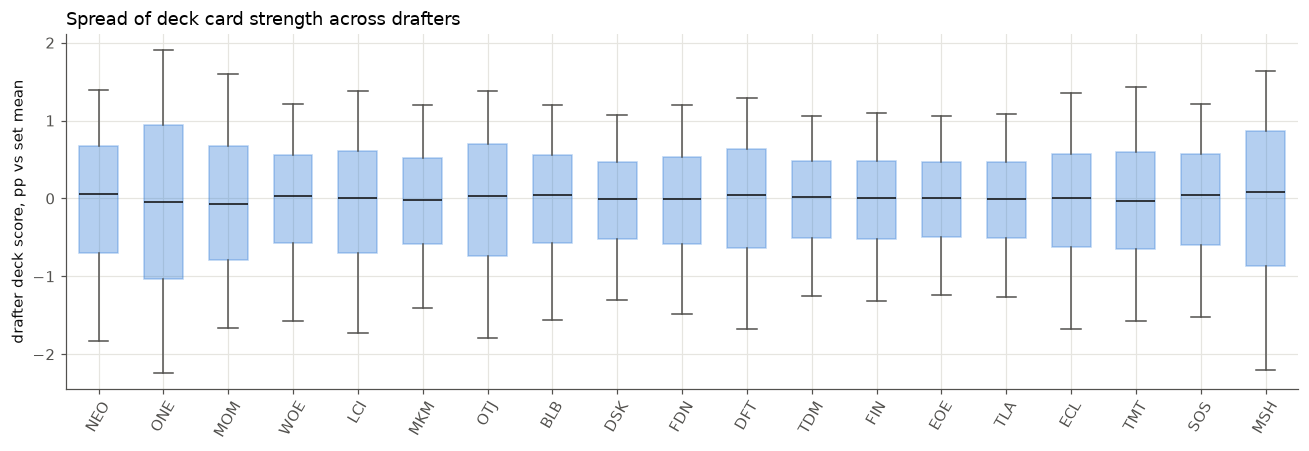

In [6]:
dist = []
for s in SETS:
    dr = games.filter(pl.col("set") == s).group_by("draft_id").agg(pl.col("score_c").mean(), pl.len()).filter(pl.col("len") >= 3)
    dist.append(dr["score_c"].to_numpy())
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.boxplot(dist, whis=(5, 95), showfliers=False, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor=BLUE, alpha=0.35, edgecolor=BLUE), medianprops=dict(color=INK),
           whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
ax.set_xticks(range(1, len(SETS) + 1), SETS, rotation=60)
ax.set_ylabel("drafter deck score, pp vs set mean")
ax.set_title("Spread of deck card strength across drafters", loc="left")
plt.tight_layout(); plt.show()

## 3. Bombs

Section 2 shows that the card ratings (shrunk normalized GIH WR, Premier Draft) predict games won, at
~5 pp of game win rate per +1 pp of deck average. This section looks at the distribution of those ratings within each set and
calls a card a **bomb** if it's an upper outlier.

**Definition.** Within each set, a card is a bomb if its rating is above the **Tukey upper fence**, Q3 + 1.5 × IQR. That's
the standard boxplot outlier rule. It uses the set's own middle 50% of cards as the yardstick, so a weak set's
filler doesn't stretch it. It's easiest to read on a robust z scale, z = (rating − median) / (IQR / 1.349). On that scale, IQR / 1.349 is the
SD a normal distribution with the same IQR would have, and the fence sits at **z = 2.70**. If ratings were normal, only 0.35% of
cards (about one per set) would clear it, so any excess over that is a fat right tail.

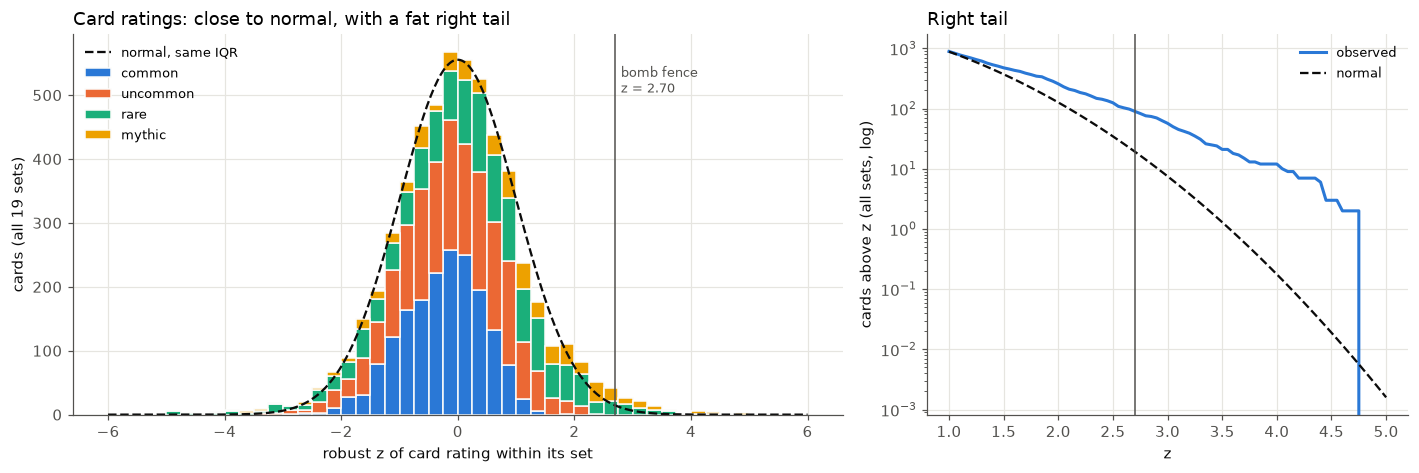

cards: 5568, above the fence: 90 (normal would give 19); below the lower fence: 69
  z > 2.00: 13.6 cards per set (normal: 6.7)
  z > 2.50: 6.6 cards per set (normal: 1.8)
  z > 2.70: 4.7 cards per set (normal: 1.0)
  z > 3.00: 3.0 cards per set (normal: 0.4)
  z > 3.50: 1.1 cards per set (normal: 0.1)


In [7]:
FENCE_Z = 0.6745 + 1.5 * 1.349   # Q3 + 1.5 IQR, in units of IQR / 1.349
from scipy.stats import norm

r = (cards.filter(pl.col("event") == "PremierDraft")
     .with_columns(pl.col("norm_eb").median().over("set").alias("med"),
                   ((pl.col("norm_eb").quantile(0.75) - pl.col("norm_eb").quantile(0.25)) / 1.349).over("set").alias("sig"))
     .with_columns(((pl.col("norm_eb") - pl.col("med")) / pl.col("sig")).alias("z"))
     .with_columns((pl.col("z") > FENCE_Z).alias("bomb")))
z = r["z"].to_numpy()

RARITIES = ["common", "uncommon", "rare", "mythic"]
R_COLOR = dict(zip(RARITIES, [BLUE, ORANGE, AQUA, YELLOW]))
bins = np.arange(-6, 6.01, 0.25)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
bottom = np.zeros(len(bins) - 1)
for k in RARITIES:
    h, _ = np.histogram(z[r["rarity"].to_numpy() == k], bins)
    ax.bar(bins[:-1], h, width=0.25, align="edge", bottom=bottom, color=R_COLOR[k], edgecolor=SURFACE, lw=1, label=k)
    bottom += h
xs = np.linspace(-6, 6, 400)
ax.plot(xs, norm.pdf(xs) * len(z) * 0.25, color=INK, lw=1.5, ls="--", label="normal, same IQR")
ax.axvline(FENCE_Z, color=MUTED, lw=1)
ax.text(FENCE_Z + 0.1, ax.get_ylim()[1] * 0.92, "bomb fence\nz = 2.70", fontsize=8.5, color=MUTED, va="top")
ax.set_xlabel("robust z of card rating within its set"); ax.set_ylabel("cards (all 19 sets)")
ax.set_title("Card ratings: close to normal, with a fat right tail", loc="left"); ax.legend(fontsize=8.5)

ax = axes[1]   # the right tail on a log scale: observed cards above z vs a normal
zz = np.linspace(1, 5, 81)
ax.semilogy(zz, [(z > t).sum() for t in zz], color=BLUE, label="observed")
ax.semilogy(zz, norm.sf(zz) * len(z), color=INK, ls="--", lw=1.5, label="normal")
ax.axvline(FENCE_Z, color=MUTED, lw=1)
ax.set_xlabel("z"); ax.set_ylabel("cards above z (all sets, log)")
ax.set_title("Right tail", loc="left"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

print(f"cards: {len(z)}, above the fence: {(z > FENCE_Z).sum()} (normal would give {norm.sf(FENCE_Z) * len(z):.0f}); "
      f"below the lower fence: {(z < -FENCE_Z).sum()}")
for t in [2.0, 2.5, FENCE_Z, 3.0, 3.5]:
    print(f"  z > {t:.2f}: {(z > t).sum() / len(SETS):.1f} cards per set (normal: {norm.sf(t) * len(z) / len(SETS):.1f})")

### 3a. The bombs in each set

`fence` is the bomb cutoff in pp above the set's average win rate. `bombs` is how many cards clear it, with their
rarity mix. The cards are listed with their rating in pp.

In [8]:
bombs = r.filter(pl.col("bomb"))
fences = r.group_by("set").agg((pl.col("med") + FENCE_Z * pl.col("sig")).first().alias("fence"),
                               pl.len().alias("cards"))
rows = []
for s in SETS:
    b = bombs.filter(pl.col("set") == s).sort("norm_eb", descending=True)
    rows.append({"set": s, "cards": fences.filter(pl.col("set") == s)["cards"][0],
                 "fence": fences.filter(pl.col("set") == s)["fence"][0], "bombs": b.height,
                 **{k[0].upper(): (b["rarity"] == k).sum() for k in RARITIES},
                 "cards (pp)": ", ".join(f"{n} {v:+.1f}" for n, v in zip(b["name"], b["norm_eb"]))})
bomb_tbl = pl.DataFrame(rows)
with pl.Config(fmt_str_lengths=400, tbl_width_chars=600):
    display(bomb_tbl)
print("bombs by rarity, all sets:", dict(bombs["rarity"].value_counts().iter_rows()))

set,cards,fence,bombs,C,U,R,M,cards (pp)
str,i64,f64,i64,i64,i64,i64,i64,str
"""NEO""",280,9.63,5,0,0,3,2,"""Jugan Defends the Temple +12.7, Fable of the Mirror-Breaker +11.6, The Wandering Emperor +11.2, Inventive Iteration +10.4, Farewell +10.4"""
"""ONE""",260,10.57,2,0,0,1,1,"""Nissa, Ascended Animist +12.1, Migloz, Maze Crusher +12.0"""
"""MOM""",341,8.80,7,0,0,5,2,"""Elesh Norn, Grand Cenobite +12.5, Sunfall +12.2, Chrome Host Seedshark +10.1, Boon-Bringer Valkyrie +9.5, Zephyr Singer +9.0, Sheoldred +9.0, Glissa, Herald of Predation +8.8"""
"""WOE""",307,9.24,2,0,0,1,1,"""Gruff Triplets +13.7, Virtue of Persistence +11.1"""
"""LCI""",285,8.92,10,0,0,7,3,"""Bonehoard Dracosaur +14.9, Aclazotz, Deepest Betrayal +13.5, Palani's Hatcher +12.0, Kitesail Larcenist +10.2, Unstable Glyphbridge +9.9, Magmatic Galleon +9.9, Sanguine Evangelist +9.8, Huatli, Poet of Unity +9.7, Breeches, Eager Pillager +9.5, Sentinel of the Nameless City +9.1"""
"""MKM""",303,8.56,3,0,0,1,2,"""Aurelia's Vindicator +13.3, Izoni, Center of the Web +10.1, Agrus Kos, Spirit of Justice +8.7"""
"""OTJ""",368,8.87,8,0,0,2,6,"""Bonny Pall, Clearcutter +12.1, Railway Brawler +11.0, Overwhelming Forces +10.5, Oko, Thief of Crowns +10.0, Vaultborn Tyrant +9.9, Rakdos, the Muscle +9.7, Roxanne, Starfall Savant +9.5, Bristly Bill, Spine Sower +9.3"""
"""BLB""",268,9.13,6,0,0,4,2,"""Season of Loss +11.0, Sword of Fire and Ice +10.1, Dreamdew Entrancer +10.0, Valley Questcaller +9.7, Mabel, Heir to Cragflame +9.3, Fecund Greenshell +9.3"""
"""DSK""",275,8.47,8,0,0,4,4,"""Overlord of the Mistmoors +13.6, Valgavoth's Onslaught +11.4, Unholy Annex // Ritual Chamber +10.2, The Swarmweaver +9.9, Ghostly Dancers +9.8, Overlord of the Boilerbilges +9.5, Overlord of the Floodpits +8.6, Tyvar, the Pummeler +8.5"""


bombs by rarity, all sets: {'mythic': 45, 'rare': 45}


### 3b. How often do you see one?

From the 17Lands draft logs (no pick data for NEO or ONE):

* **Opened packs.** The pack at pick 1 of each round is a whole freshly opened 14-card pack. `P(pack)` is the share of
  those packs with at least one bomb. `per pod` is the expected number of bombs opened at an 8-player table (24 packs).
* **Final pool.** Every card the drafter picked (42). `P(pool ≥1)` and `P(pool ≥2)` are the share of complete drafts
  with at least one or two bombs. This is what 17Lands users actually end up with, and they're above-average drafters
  who take bombs when they see them.

In [9]:
def bomb_freq(s):
    lf = pl.scan_parquet(ROOT / "data" / "parquet" / f"{s}.PremierDraft.parquet")
    names = set(bombs.filter(pl.col("set") == s)["name"])
    cols = [f"pack_card_{n}" for n in names if f"pack_card_{n}" in lf.collect_schema().names()]
    n = lf.group_by("draft_id").len()
    full = n.filter(pl.col("len") == pl.col("len").mode().first()).select("draft_id")
    packs = (lf.filter(pl.col("pick_number") == 0)
             .select(pl.sum_horizontal(cols).alias("b") if cols else pl.lit(0).alias("b")).collect()["b"].to_numpy())
    pool = (lf.join(full, on="draft_id").group_by("draft_id").agg(pl.col("pick").is_in(list(names)).sum().alias("b"))
            .collect()["b"].to_numpy())
    return {"set": s, "bombs": len(names), "P(pack)": (packs > 0).mean(), "per pod": packs.mean() * 24,
            "P(pool ≥1)": (pool >= 1).mean(), "P(pool ≥2)": (pool >= 2).mean(), "mean in pool": pool.mean(),
            "drafts": len(pool)}

DRAFT_SETS = [s for s in SETS if (ROOT / "data" / "parquet" / f"{s}.PremierDraft.parquet").exists()]
freq = pl.DataFrame([bomb_freq(s) for s in DRAFT_SETS])
freq.write_csv(OUT / "bomb_frequency.csv")
display(freq)
print("median over sets:", {k: round(float(freq[k].median()), 3) for k in freq.columns[1:-1]})

set,bombs,P(pack),per pod,P(pool ≥1),P(pool ≥2),mean in pool,drafts
str,i64,f64,f64,f64,f64,f64,i64
"""MOM""",7,0.08,2.01,0.25,0.03,0.27,205437
"""WOE""",2,0.02,0.52,0.07,0.00,0.07,165792
"""LCI""",10,0.11,2.70,0.31,0.05,0.36,134970
"""MKM""",3,0.04,0.84,0.11,0.01,0.12,157553
"""OTJ""",8,0.07,1.77,0.22,0.02,0.24,195312
"""BLB""",6,0.08,1.96,0.23,0.03,0.26,154585
"""DSK""",8,0.11,2.58,0.30,0.04,0.35,167672
"""FDN""",0,0.00,0.00,0.00,0.00,0.00,130935
"""DFT""",6,0.07,1.61,0.19,0.02,0.22,141166


median over sets: {'bombs': 3.0, 'P(pack)': 0.045, 'per pod': 1.081, 'P(pool ≥1)': 0.154, 'P(pool ≥2)': 0.01, 'mean in pool': 0.164}


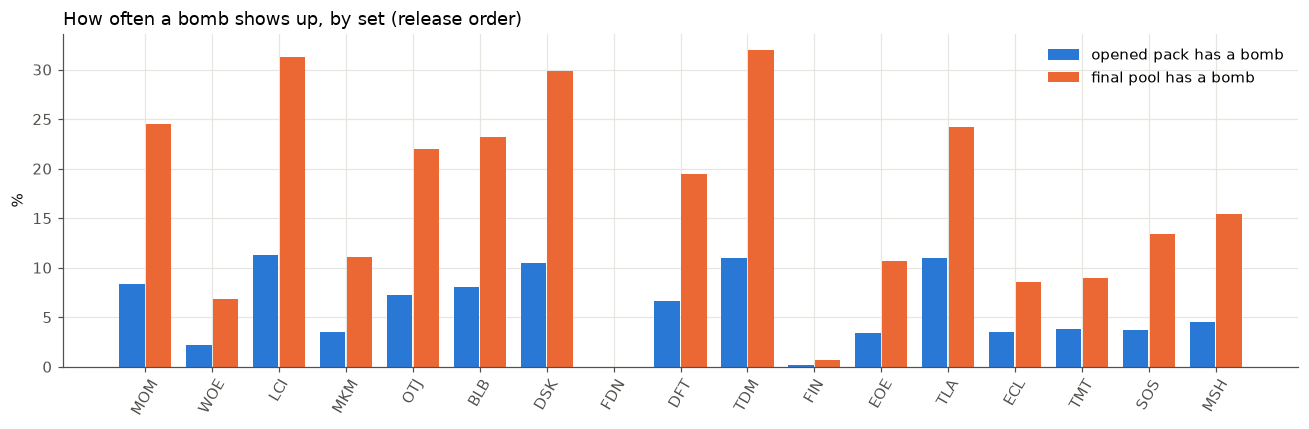

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(freq.height)
ax.bar(x - 0.2, freq["P(pack)"] * 100, width=0.38, color=BLUE, label="opened pack has a bomb")
ax.bar(x + 0.2, freq["P(pool ≥1)"] * 100, width=0.38, color=ORANGE, label="final pool has a bomb")
ax.set_xticks(x, freq["set"], rotation=60); ax.set_ylabel("%")
ax.set_title("How often a bomb shows up, by set (release order)", loc="left"); ax.legend()
plt.tight_layout(); plt.show()